<a href="https://colab.research.google.com/github/Krinz-hub/AI_Smart_Study_Planner_Student_Product_Spec/blob/main/linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd


In [ ]:

import pandas as pd

df = pd.read_csv("/content/appliance_electricity_consumption_with_nans.csv")

print(df.head())
print("Shape:", df.shape)
print("\nMissing values per column:")
print(df.isna().sum())


   household_size  home_area_sqft  outside_temperature_c  \
0             7.0           695.7                   30.0   
1             2.0          1274.1                   31.4   
2             1.0          1816.9                   31.1   
3             6.0           646.6                   32.4   
4             3.0           913.9                   19.9   

   indoor_temperature_setting_c  occupants_home_hours_per_day  is_weekend  \
0                          25.4                          13.5           0   
1                          22.5                          14.4           1   
2                          21.1                           6.2           0   
3                          24.5                          12.4           1   
4                          24.2                           8.1           0   

    season  ac_power_w  ac_hours_per_day  refrigerator_power_w  ...  \
0   summer        2200              2.51                 150.0  ...   
1   spring         900            

In [ ]:
df.dropna(inplace=True)

In [ ]:
x=df.drop(columns=["daily_consumption_kwh",
    "monthly_consumption_kwh"])

In [ ]:
y = df["daily_consumption_kwh"]

In [ ]:
x = pd.get_dummies(x, columns=["season"], dtype=int)


In [ ]:
from sklearn.impute import SimpleImputer

In [ ]:
imputer = SimpleImputer(strategy="median")
x = pd.DataFrame(
    imputer.fit_transform(x),
    columns=x.columns,
    index=x.index
)


In [ ]:
x.shape


(9911, 24)

In [ ]:
y.shape

(9911,)

In [ ]:
from sklearn.linear_model import LinearRegression as lr

In [ ]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
model=lr()
model.fit(x_train,y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(x_test)

In [ ]:
print("First 10 predictions:", y_pred[:10])


First 10 predictions: [10.37337849 14.35882474 11.1982937  11.34556887 14.70648989 12.68106818
 12.43438139 10.46098561 13.62912754  9.32800984]


In [ ]:
from sklearn.metrics import r2_score

In [ ]:
print(r2_score(y_test,y_pred)  )

0.8245571103482783


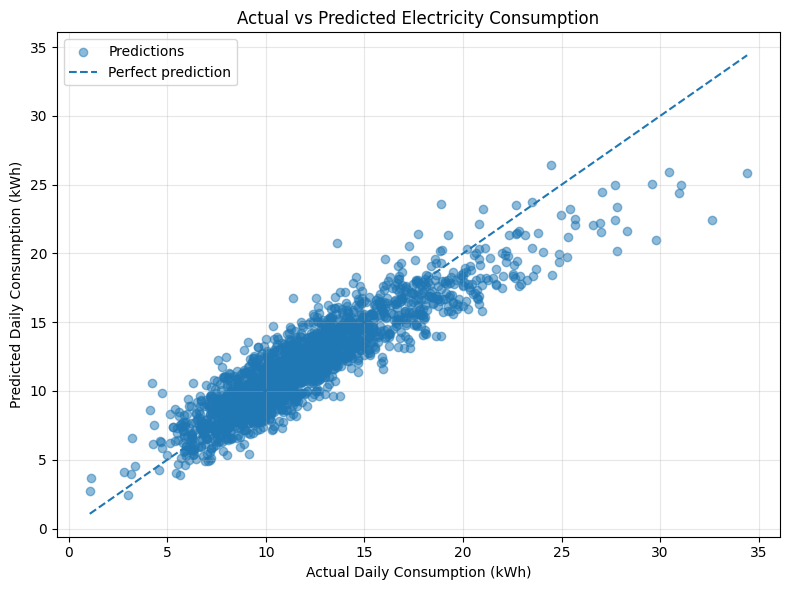

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5, label="Predictions")

# Perfect prediction reference line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Daily Consumption (kWh)")
plt.ylabel("Predicted Daily Consumption (kWh)")
plt.title("Actual vs Predicted Electricity Consumption")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


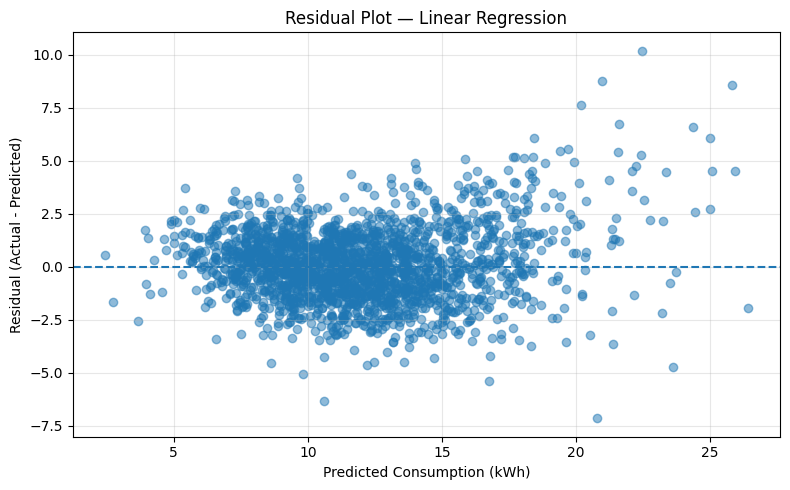

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Consumption (kWh)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot — Linear Regression")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
